# 11-12 | Paare bilden und bekanntes Wissen nutzen

Zwei getrennte Lehrtermine mit je zwei Aufgaben zu 15 Minuten.
**Vorwissen:** Integral als Mittelwert, SE, unabhaengige Wiederholungen,
Paarzuordnung und Budgetvergleich aus 06-10.
Wir schaetzen weiter den Mittelwert von sqrt(U) fuer U gleichverteilt
auf [0,1]. Die Referenz 2/3 ist nur zur Kontrolle bekannt.
Alle Basiszellen sind ausfuehrbar. Antworten in neuen Zellen ergaenzen.
**Umgebung:** Kurskernel mit NumPy, SciPy und Matplotlib; keine Downloads
oder externen Daten. Die groesseren Studien am Ende sind freiwillig.
**Arbeitsweg:** In Termin 11 nur bis zum ersten Haltepunkt arbeiten.
Nach einem Kernelneustart fuer Termin 12 zuerst die Basiszellen aus 11
bis zu diesem Haltepunkt ausfuehren; die Loesungszellen sind nicht noetig.
**Werkzeugcode:** Die Hilfsfunktionen einmal ausfuehren, nicht neu entwickeln.
Pflicht sind Paarmittel, Korrekturregel, Budget und Ergebnisdeutung.
Arraypruefungen, t-Quantile und die Pilotformel sind keine Programmieraufgabe.

In [1]:
import math
from statistics import mean, stdev

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t

plt.rcParams.update({"font.size": 13})


def schaetzbericht(werte):
    daten = np.asarray(werte, dtype=float)
    if daten.ndim != 1 or len(daten) < 2 or not np.all(np.isfinite(daten)):
        raise ValueError("Mindestens zwei endliche Auswertungseinheiten erforderlich")
    standardfehler = float(daten.std(ddof=1) / math.sqrt(len(daten)))
    schaetzung = float(daten.mean())
    halbbreite = float(t.ppf(0.975, len(daten) - 1)) * standardfehler
    return {"schaetzung": schaetzung, "standardfehler": standardfehler,
            "unten": schaetzung - halbbreite, "oben": schaetzung + halbbreite,
            "einheiten": len(daten)}


def paarmittel(eingaben, funktion=np.sqrt):
    daten = np.asarray(eingaben, dtype=float)
    if daten.ndim != 1 or len(daten) == 0 or not np.all(np.isfinite(daten)) or np.any((daten < 0) | (daten > 1)):
        raise ValueError("Endliche Eingaben aus [0,1] erforderlich")
    links = np.asarray(funktion(daten), dtype=float)
    rechts = np.asarray(funktion(1 - daten), dtype=float)
    if links.shape != daten.shape or rechts.shape != daten.shape or not np.all(np.isfinite([links, rechts])):
        raise ValueError("Funktion muss einen endlichen Wert je Eingabe liefern")
    return ((links + rechts) / 2).tolist()


print("Ein Paar bei u=0.2:", paarmittel([0.2]))

Ein Paar bei u=0.2: [0.6708203932499369]


## Termin 11 | Antithetische Variablen

Statt zwei unabhaengige Eingaben zu ziehen, verwenden wir u und 1-u.
Beide sind einzeln gleichverteilt; innerhalb des Paars sind sie abhaengig.
Zuerst beide Funktionswerte mitteln, danach die unabhaengigen Paarmittel
auswerten. Bei 2000 Funktionsauswertungen bleiben 1000 Paarmittel.
Der SE ist deren Stichproben-Standardabweichung geteilt durch sqrt(1000),
nicht durch sqrt(2000). Der naive Vergleich nutzt 2000 unabhaengige Werte.

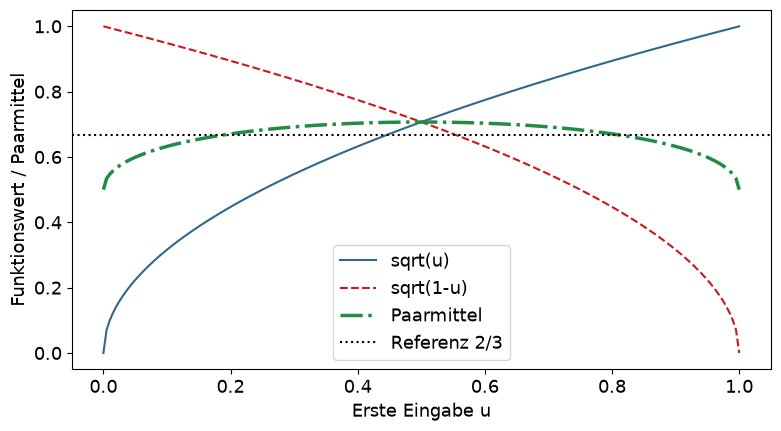

In [2]:
achse_u = np.linspace(0, 1, 201)
figur, achse = plt.subplots(figsize=(8, 4.5))
achse.plot(achse_u, np.sqrt(achse_u), label="sqrt(u)", color="#31688e")
achse.plot(achse_u, np.sqrt(1 - achse_u), label="sqrt(1-u)", color="#cb181d", linestyle="--")
achse.plot(achse_u, paarmittel(achse_u), label="Paarmittel", color="#238b45", linewidth=2.5, linestyle="-.")
achse.axhline(2 / 3, color="black", linestyle=":", label="Referenz 2/3")
achse.set(xlabel="Erste Eingabe u", ylabel="Funktionswert / Paarmittel")
achse.legend()
figur.tight_layout()
plt.show()

In [3]:
def antithetik_vergleich(budget, seed, funktion=np.sqrt):
    if not isinstance(budget, int) or budget < 4 or budget % 2:
        raise ValueError("Gerades Budget ab vier Funktionsauswertungen erforderlich")
    strom_naiv, strom_paare = np.random.default_rng(seed).spawn(2)
    naiv = schaetzbericht(funktion(strom_naiv.random(budget)))
    anti = schaetzbericht(paarmittel(strom_paare.random(budget // 2), funktion))
    return {"budget": budget, "naiv": naiv, "antithetik": anti}


antibericht = antithetik_vergleich(2000, 42)
print(antibericht)

{'budget': 2000, 'naiv': {'schaetzung': 0.6692751004580285, 'standardfehler': 0.005196986971924365, 'unten': 0.6590830220774312, 'oben': 0.6794671788386258, 'einheiten': 2000}, 'antithetik': {'schaetzung': 0.6645736740131004, 'standardfehler': 0.0014083229823279788, 'unten': 0.6618100634342111, 'oben': 0.6673372845919897, 'einheiten': 1000}}


Ein gerades Budget ist hier Teil der Schnittstelle. Ein ungerades Budget
wird nicht still abgerundet und kein einzelner Restwert falsch gewichtet.
Die t-Intervalle sind naeherungsweise; es gibt keine Deckungsgarantie fuer
winzige Stichproben. Gleiche Auswertungszahl ist nicht gleiche Laufzeit.

## A11.1 | Vier Paare von Hand | 15 Minuten

Fuer u = [0.04, 0.16, 0.36, 0.64]: Ergaenzen Sie 1-u, sqrt(u), sqrt(1-u)
und das Paarmittel. Mitteln Sie die vier Paarmittel. Wie viele Paarmittel
und wie viele Funktionswerte liegen vor? Welche Einheiten waeren unabhaengig,
wenn die vier Basiswerte u unabhaengig zufaellig gezogen wuerden?
CR11.1 kann den Programmierteil ersetzen. Taschenrechner ist erlaubt.

## A11.2 | Gleiches Budget | 15 Minuten

Vergleichen Sie mit `antithetik_vergleich` bei Budget 2000 und Seed 42 die
beiden Schaetzungen, SEs und Intervalle. Wiederholen Sie mit Seed 43.
Erklaeren Sie, warum die 2000 antithetischen Einzelwerte nicht unabhaengig sind.
**Start:** Kopieren Sie `antibericht = antithetik_vergleich(2000, 42)` in
eine eigene Zelle. `antibericht["antithetik"]["standardfehler"]` liefert
den SE der Paarmethode; `"naiv"` waehlt die unabhaengige Vergleichsmethode.
`"schaetzung"`, `"unten"` und `"oben"` liefern die weiteren Tabellenspalten.

## Haltepunkt: Pflichtteil Termin 11 endet hier

- Zwei passende Eingaben ergeben ein Paarmittel.
- Der SE verwendet unabhaengige Paarmittel, nicht alle Einzelwerte.
- Ein Vergleich braucht dieselbe Zielgroesse und dasselbe Auswertungsbudget.
**Abschlussfrage:** Wie viele Paarmittel entstehen aus 600 Zielauswertungen?
Wahlteil 11 am Ende ist optional. Termin 12 beginnt erst nach dem Rueckblick.

## Termin 12 | Kontrollvariablen

E[U] bezeichnet den Modellmittelwert von U; hier kennen wir E[U] = 0.5 genau.
Bei zu grossen beobachteten U-Werten sind
meist auch sqrt(U)-Werte zu gross. Fuer vorgegebenes beta korrigieren wir
jeden Zielwert: z = g - beta * (h - 0.5), hier h=U und g=sqrt(U).
Die Korrektur wird aus der Abweichung der Hilfsgroesse gebildet, nicht aus
dem Fehler gegen die nur zur Kontrolle bekannte Zielreferenz 2/3.

In [4]:
def kontrollwerte(zielwerte, hilfswerte, beta, erwartungswert=0.5):
    if len(zielwerte) == 0 or len(zielwerte) != len(hilfswerte):
        raise ValueError("Gleich viele nichtleere Ziel- und Hilfswerte erforderlich")
    if not all(math.isfinite(wert) for wert in [*zielwerte, *hilfswerte, beta, erwartungswert]):
        raise ValueError("Alle Werte muessen endlich sein")
    return [ziel - beta * (hilfe - erwartungswert) for ziel, hilfe in zip(zielwerte, hilfswerte)]


print("Ein Wert: g=0.8, h=0.64, beta=1:", kontrollwerte([0.8], [0.64], 1))

Ein Wert: g=0.8, h=0.64, beta=1: [0.66]


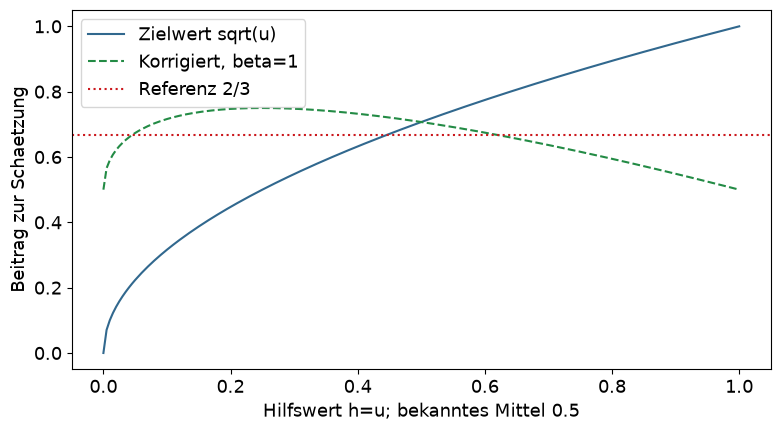

In [5]:
figur, achse = plt.subplots(figsize=(8, 4.5))
achse.plot(achse_u, np.sqrt(achse_u), label="Zielwert sqrt(u)", color="#31688e")
achse.plot(achse_u, kontrollwerte(np.sqrt(achse_u), achse_u, 1),
           label="Korrigiert, beta=1", color="#238b45", linestyle="--")
achse.axhline(2 / 3, color="#cb181d", linestyle=":", label="Referenz 2/3")
achse.set(xlabel="Hilfswert h=u; bekanntes Mittel 0.5", ylabel="Beitrag zur Schaetzung")
achse.legend()
figur.tight_layout()
plt.show()

## Pilot und Hauptlauf sauber trennen

Fuer einen festen oder unabhaengig bestimmten Koeffizienten ist der
erwartete Korrekturterm null. Ein aus denselben Hauptdaten geschaetztes beta
ist dagegen nicht einfach eine Konstante in diesem Argument.
Wir verwenden deshalb einen separaten Pilot, frieren beta ein und schaetzen
ausschliesslich mit frischen Hauptdaten. Pilotkosten zaehlen zum Budget.

In [6]:
def pilot_beta(zielwerte, hilfswerte):
    kontrollwerte(zielwerte, hilfswerte, 0)
    if len(zielwerte) < 2:
        raise ValueError("Mindestens zwei Pilotwerte erforderlich")
    zielmittel = mean(zielwerte)
    hilfsmittel = mean(hilfswerte)
    nenner = sum((hilfe - hilfsmittel) ** 2 for hilfe in hilfswerte)
    if nenner == 0:
        raise ValueError("Hilfsgroesse muss im Pilot streuen")
    return sum((ziel - zielmittel) * (hilfe - hilfsmittel)
               for ziel, hilfe in zip(zielwerte, hilfswerte)) / nenner


def kontrollvergleich(gesamtbudget, pilotumfang, seed):
    if not all(isinstance(anzahl, int) for anzahl in [gesamtbudget, pilotumfang]):
        raise ValueError("Ganze Umfaenge erforderlich")
    if pilotumfang < 2 or gesamtbudget - pilotumfang < 2:
        raise ValueError("Mindestens zwei Pilot- und zwei Hauptwerte erforderlich")
    strom_pilot, strom_haupt, strom_naiv = np.random.default_rng(seed).spawn(3)
    hilfe_pilot = strom_pilot.random(pilotumfang).tolist()
    ziel_pilot = [math.sqrt(wert) for wert in hilfe_pilot]
    beta = pilot_beta(ziel_pilot, hilfe_pilot)
    hilfe_haupt = strom_haupt.random(gesamtbudget - pilotumfang).tolist()
    ziel_haupt = [math.sqrt(wert) for wert in hilfe_haupt]
    korrigiert = schaetzbericht(kontrollwerte(ziel_haupt, hilfe_haupt, beta))
    naiv = schaetzbericht(np.sqrt(strom_naiv.random(gesamtbudget)))
    return {"gesamtbudget": gesamtbudget, "pilotumfang": pilotumfang, "beta": beta,
            "hauptumfang": len(hilfe_haupt), "kontrolliert": korrigiert, "naiv": naiv}


kontrollbericht = kontrollvergleich(2000, 500, 42)
print(kontrollbericht)

{'gesamtbudget': 2000, 'pilotumfang': 500, 'beta': 0.8015206745011789, 'hauptumfang': 1500, 'kontrolliert': {'schaetzung': 0.6663024536420868, 'standardfehler': 0.0011968117648053, 'unten': 0.6639548501451125, 'oben': 0.6686500571390612, 'einheiten': 1500}, 'naiv': {'schaetzung': 0.6657980121786168, 'standardfehler': 0.005289024750353003, 'unten': 0.6554254337781448, 'oben': 0.6761705905790888, 'einheiten': 2000}}


Der kontrollierte SE bezieht sich auf den Hauptlauf bei eingefrorenem beta.
Wiederholungen des ganzen Pilot-Haupt-Verfahrens pruefen zusaetzlich dessen
Streuung. Der naive Vergleich bekommt ebenso 2000 Zielauswertungen, waehrend
die Kontrollmethode davon 500 fuer den Pilot und 1500 fuer die Schaetzung nutzt.
Hilfswerte und Koeffizientenschaetzung kosten zusaetzlich Zeit; hier wird
nur das Budget der Zielauswertungen gleichgesetzt, keine Laufzeit versprochen.

## A12.1 | Eine bekannte Abweichung korrigieren | 15 Minuten

Vorgegeben g=[0.2,0.4,0.6,0.8], h=[0.04,0.16,0.36,0.64], beta=1 und
bekannter Hilfsmittelwert 0.5: Berechnen Sie die vier korrigierten Werte
und ihren Mittelwert. Vergleichen Sie mit dem unkorrigierten Mittelwert.
Warum muss eine Korrektur nicht in jeder einzelnen Stichprobe besser sein?
CR12.1 kann den Programmierteil ersetzen.

## A12.2 | Pilot und Hauptlauf | 15 Minuten

Fuehren Sie `kontrollvergleich(2000, 500, 43)` aus. Notieren Sie beta,
Hauptumfang, Schaetzung und SE beider Methoden. Begruenden Sie, warum der
Pilot nicht noch einmal als Hauptdaten verwendet wird und zum Budget zaehlt.
**Hilfe:** Alle 2000 Zielauswertungen zaehlen; nur 1500 tragen zur CV-Schaetzung bei.
Schreiben Sie `bericht = kontrollvergleich(2000, 500, 43)` in eine neue Zelle.
`bericht["beta"]` ist der Koeffizient, `bericht["hauptumfang"]` die Zahl
frischer Hauptwerte. Unter `"kontrolliert"` und `"naiv"` stehen jeweils
`"schaetzung"` und `"standardfehler"`. Die Hilfsfunktionen bleiben unveraendert.

## Pflichtteil Termin 12 endet hier

- Korrigiert wird mit bekanntem Wissen ueber eine Hilfsgroesse.
- Der Pilot bestimmt beta, frische Hauptdaten bestimmen die Schaetzung.
- Pilotkosten und Unsicherheit gehoeren zum Methodenvergleich.
**Abschlussfrage:** Was aendert sich bei beta=0?
**Naechster Termin:** Den Eingaberaum mit Schichten und LHS abdecken.

## Wahlteil 11 | Monotonie und ein korrigiertes Gegenbeispiel

Bei gleichem Budget ist negative Kovarianz innerhalb eines Paars hilfreich.
Monotonie ist hinreichend fuer nichtpositive Kovarianz, aber nicht notwendig.
Eine konstante Funktion gewinnt nicht strikt. Das alte Gegenbeispiel
cos(5*pi*u) war falsch: cos(5*pi*(1-u)) = -cos(5*pi*u), das Paarmittel ist null.
cos(2*pi*u) ist dagegen symmetrisch: Beide Werte im Paar sind gleich.
Bei gleichem Auswertungsbudget verdoppelt sich dann theoretisch die Varianz
gegenueber unabhaengigen Werten. Schaden ist also durchaus moeglich.
In der folgenden sqrt-Studie liegt der beobachtete SE-Faktor bei etwa
3.6 bis 3.8, nicht bei den 10 bis 12 der alten Loesung. Varianzfaktoren
sind die Quadrate der SE-Faktoren; Laufzeitgewinne sind damit nicht gemessen.

In [7]:
def kosinus_fuenf(eingaben):
    return np.cos(5 * np.pi * eingaben)


def kosinus_zwei(eingaben):
    return np.cos(2 * np.pi * eingaben)


print("Altes Gegenbeispiel, Paarmittel:", paarmittel([0.13, 0.29, 0.63], kosinus_fuenf))
print("Tatsaechlich unguenstig:", antithetik_vergleich(2000, 42, kosinus_zwei))
for budget in [1000, 10000, 100000]:
    ergebnis = antithetik_vergleich(budget, 42)
    print("UEB3 Antithetik:", budget, ergebnis,
          "SE-Faktor:", ergebnis["naiv"]["standardfehler"] / ergebnis["antithetik"]["standardfehler"])

normalstrom = np.random.default_rng(42)
normalwerte = normalstrom.standard_normal(100000)
normalpaare = (np.exp(normalwerte) + np.exp(-normalwerte)) / 2
print("KAP3 lognormal: 200000 Auswertungen, 100000 Paare:", schaetzbericht(normalpaare))
print("Referenz:", math.exp(0.5))

Altes Gegenbeispiel, Paarmittel: [6.661338147750939e-16, -7.355227538141662e-16, 5.551115123125783e-17]
Tatsaechlich unguenstig: {'budget': 2000, 'naiv': {'schaetzung': -0.016707282771493245, 'standardfehler': 0.01587684982709156, 'unten': -0.04784418935772859, 'oben': 0.0144296238147421, 'einheiten': 2000}, 'antithetik': {'schaetzung': 0.03644267473941343, 'standardfehler': 0.02222101410655351, 'unten': -0.007162542550307779, 'oben': 0.08004789202913463, 'einheiten': 1000}}
UEB3 Antithetik: 1000 {'budget': 1000, 'naiv': {'schaetzung': 0.6727684687568604, 'standardfehler': 0.007279543772319448, 'unten': 0.6584835181943021, 'oben': 0.6870534193194187, 'einheiten': 1000}, 'antithetik': {'schaetzung': 0.6608126622156069, 'standardfehler': 0.00203787405222346, 'unten': 0.6568087911700723, 'oben': 0.6648165332611414, 'einheiten': 500}} SE-Faktor: 3.572126434593427
UEB3 Antithetik: 10000 {'budget': 10000, 'naiv': {'schaetzung': 0.6658652814401307, 'standardfehler': 0.002346478883790469, 'unt

Die symmetrische Normalziehung Z/-Z ersetzt hier die urspruengliche
inverse Normaltransformation von U/1-U und vermeidet deren unendliche Randwerte.
Die zusaetzlichen mehrdimensionalen Einflussbeispiele bleiben spaetere Vertiefung.

## Wahlteil 12 | Koeffizient und Wiederholungsstudie

Optimaler fester Koeffizient: beta = Cov(g,h)/Var(h), wenn Var(h)>0.
Hier analytisch 0.8. Die verbleibende Varianz ist beim optimalen Koeffizienten
der Anteil 1-rho^2 der urspruenglichen Varianz, nicht deren Kehrwert.
Ein unpassender Koeffizient kann die Streuung vergroessern; ein falscher
angeblich bekannter Hilfsmittelwert verzerrt das Ergebnis.
Die urspruenglichen Hauptumfaenge 5000/50000 werden unten mit einem
separaten Pilot von 50000 beibehalten. Der naive Lauf erhaelt das gleiche
Gesamtbudget. Das ist bewusst ein anderer Budgetvergleich als nur Hauptdaten.

In [8]:
for hauptumfang in [5000, 50000]:
    wiederholungen = [kontrollvergleich(hauptumfang + 50000, 50000, seed) for seed in range(1000, 1020)]
    streuung_cv = stdev([bericht["kontrolliert"]["schaetzung"] for bericht in wiederholungen])
    streuung_naiv = stdev([bericht["naiv"]["schaetzung"] for bericht in wiederholungen])
    print("UEB3 CV:", "Hauptumfang", hauptumfang, "Pilotumfang", 50000,
          "Streuung ganzer Laeufe CV/naiv", streuung_cv, streuung_naiv,
          "Reduktion in Prozent", 100 * (1 - streuung_cv / streuung_naiv))

UEB3 CV: Hauptumfang 5000 Pilotumfang 50000 Streuung ganzer Laeufe CV/naiv 0.0005106615949954222 0.0009115362356326616 Reduktion in Prozent 43.9779160681427


UEB3 CV: Hauptumfang 50000 Pilotumfang 50000 Streuung ganzer Laeufe CV/naiv 0.00017747715147765206 0.0006892585972985865 Reduktion in Prozent 74.25100649114297


Die Laufstreuung schaetzt den SE **eines** vollstaendigen Verfahrenslaufs;
sie wird nicht durch sqrt(20) geteilt. Letzteres waere der SE des Mittels
aller 20 Schaetzungen, also eine andere Zielgroesse mit hoeherem Gesamtbudget.
Die endliche Studie belegt keine universelle Verbesserung.
Mehrere Kontrollen, Matrixform, Cross-Fitting und das Coupon-Collector-Beispiel
bleiben als weitergehende Originalthemen in der offenen Themenliste sichtbar.